# Challenge · rockfall

*Book 3 · Probability · Shelf I -- the book's closing challenge*

**The question.** A protection net above a road catches falling rocks from two zones of a slope.
From one season of observations -- three months, about 90 rocks -- how well can we estimate how often
a rock breaks through the net in a year?

**The number.** The estimated breach rate from the observed season, for four choices of the mass
distribution, against the **true** rate; then the same over 100 seasons, to see how far a single
season can mislead.

**Why we know the truth.** The slope is seeded (`ds_toolbox.rockfall`): its parameters come from the
FHNW probability challenge "Steinschlag" of 2019 -- zone 1 fitted to the 68 rocks the report prints,
zone 2 chosen so the model reproduces the report's result of about 0.016 breaches a year. The
report's course data were most likely simulated too; here the generator is open, so every estimate
can be scored against the answer.

**The net** (the report's rules): emptied daily at 08:00; a rock of 1000 kJ or more breaks through;
a rock of 500-1000 kJ breaks through if the net already holds 2000 kg.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ds_toolbox import io, tracking, viz
from ds_toolbox import rockfall as rf

viz.use_style()
FAMILIES = ["lognormal", "gamma", "weibull", "exponential"]
SEASON_MIN = 90 * 1440.0

## 1 · The truth

Every rock simulated over 100 000 years, the net's load tracked day by day.

In [2]:
truth_zones = rf.true_zones()
YEARS = 100_000
ev = rf.simulate(truth_zones, rf.MIN_PER_YEAR * YEARS, seed=2019)
breaks = rf.through_net(ev)
TRUE_RATE = breaks.sum() / YEARS
true_se = np.sqrt(breaks.sum()) / YEARS
by_zone = (ev[breaks].groupby("zone").size() / YEARS).to_dict()
print(f"true breach rate: {TRUE_RATE:.4f} +/- {true_se:.4f} a year -- one breach every {1 / TRUE_RATE:.0f} years")
print("by zone:", {k: round(v, 4) for k, v in by_zone.items()})

true breach rate: 0.0165 +/- 0.0004 a year -- one breach every 61 years
by zone: {'zone 1': 0.0, 'zone 2': 0.0164}


## 2 · The observed season

One season from the same world -- the committed sample, January to March. This is all a team on the
slope would have.

In [3]:
season = io.load_sample("rockfall_season.csv", parse_dates=["time"])
season.groupby("zone").agg(rocks=("mass", "size"), mass_mean=("mass", "mean"), mass_max=("mass", "max"),
                           speed_mean=("speed", "mean"), energy_max=("energy", "max")).round(1)

,rocks,mass_mean,mass_max,speed_mean,energy_max
zone,,,,,
zone 1,61,635.0,2657.0,8.9,183.5
zone 2,28,122.9,439.0,37.3,337.4


The largest energy observed is far below the 500 kJ where the net starts to fail. Every breach the
estimate predicts comes from beyond the data -- from the tail of a fitted distribution.

## 3 · Estimating from the season

Per zone: rocks arrive as a Poisson process at the observed rate, speeds are normal, and the mass
follows one of four families fitted by maximum likelihood. Each fitted world gives a breach rate.

In [4]:
def estimate(season_df, family, seed=0):
    zones = [rf.fit_zone(season_df, z, family, SEASON_MIN) for z in ("zone 1", "zone 2")]
    return rf.estimate_breach_rate(zones, years=1500, seed=seed)


def aic_best(season_df):
    total = {}
    for fam in FAMILIES:
        aic = 0.0
        for z in ("zone 1", "zone 2"):
            m = season_df.loc[season_df.zone == z, "mass"].to_numpy()
            f = rf.fit_mass(m, fam)
            k = 1 if fam == "exponential" else 2
            aic += 2 * k - 2 * f.logpdf(m).sum()
        total[fam] = aic
    return min(total, key=total.get), total


one = {fam: estimate(season, fam) for fam in FAMILIES}
best, aics = aic_best(season)
one_table = pd.DataFrame({"estimated breaches a year": one, "AIC (both zones)": aics})
one_table["vs truth"] = one_table["estimated breaches a year"] / TRUE_RATE
print(f"AIC picks: {best} · truth {TRUE_RATE:.4f}")
one_table.style.format({"estimated breaches a year": "{:.2e}", "AIC (both zones)": "{:.1f}",
                        "vs truth": "{:.2g}x"})

AIC picks: exponential · truth 0.0165


,estimated breaches a year,AIC (both zones),vs truth
lognormal,1.40e+00,inf,85x
gamma,1.40e-02,inf,0.85x
weibull,1.28e-02,inf,0.78x
exponential,2.74e-02,1238.8,1.7x


## 4 · A hundred seasons

One season is one draw. Repeat the whole procedure -- observe 90 days, fit, estimate -- on 100
fresh seasons from the same world, and look at the spread.

In [5]:
N_SEASONS = 100
rows = []
for k in range(N_SEASONS):
    s = rf.season(days=90, seed=10_000 + k)
    pick, _ = aic_best(s)
    for fam in FAMILIES:
        rows.append({"season": k, "family": fam, "rate": estimate(s, fam, seed=k), "aic_pick": fam == pick})
runs = pd.DataFrame(rows)
picked = runs[runs.aic_pick].assign(family="AIC's pick")
both = pd.concat([runs, picked])
ratio = both.assign(ratio=both.rate / TRUE_RATE)
summary = ratio.groupby("family")["ratio"].agg(
    median="median", p05=lambda x: x.quantile(0.05), p95=lambda x: x.quantile(0.95),
    within_2x=lambda x: ((x > 0.5) & (x < 2)).mean())
summary = summary.reindex(FAMILIES + ["AIC's pick"])
summary.style.format({"median": "{:.2g}x", "p05": "{:.2g}x", "p95": "{:.2g}x", "within_2x": "{:.0%}"})

,median,p05,p95,within_2x
family,,,,
lognormal,50x,12x,1.7e+02x,0%
gamma,0.51x,0.0016x,5.8x,33%
weibull,0.58x,0.00019x,6x,35%
exponential,0.81x,0.048x,4.6x,43%
AIC's pick,0.8x,0.001x,6.2x,38%


AIC picked, over the seasons: {'exponential': 73, 'weibull': 14, 'gamma': 12, 'lognormal': 1}


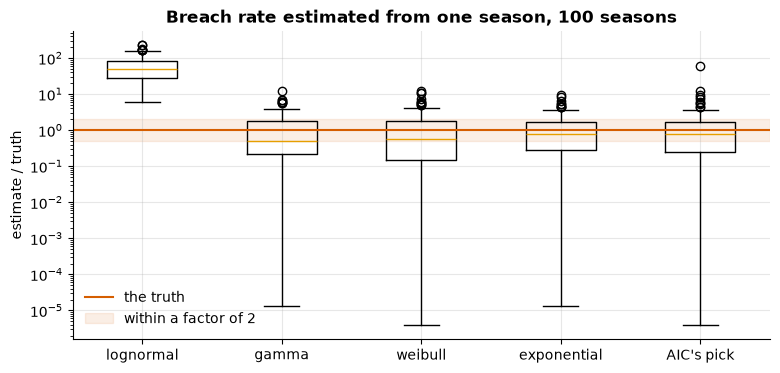

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
order = FAMILIES + ["AIC's pick"]
data = [np.clip(ratio.loc[ratio.family == f, "ratio"], 1e-6, None) for f in order]
ax.boxplot(data, tick_labels=order, showfliers=True)
ax.axhline(1, color=viz.PALETTE[3], lw=1.5, label="the truth")
ax.axhspan(0.5, 2, color=viz.PALETTE[3], alpha=0.1, label="within a factor of 2")
ax.set(yscale="log", ylabel="estimate / truth",
       title=f"Breach rate estimated from one season, {N_SEASONS} seasons")
ax.legend()
print("AIC picked, over the seasons:", runs[runs.aic_pick].family.value_counts().to_dict())

## Recorded

In [7]:
HERE = Path.cwd()
result = {
    "challenge": "rockfall",
    "true_breach_rate_per_year": round(float(TRUE_RATE), 5),
    "observed_season": {fam: round(float(r), 6) for fam, r in one.items()},
    "aic_pick_observed_season": best,
    "over_seasons": {fam: {k: round(float(v), 4) for k, v in row.items()} for fam, row in summary.iterrows()},
    "seasons": N_SEASONS,
}
(HERE / "results.json").write_text(json.dumps(result, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
_run = tracking.log_run("rockfall", {"seasons": N_SEASONS}, {"true_rate": float(TRUE_RATE)}, root=HERE,
                       use_mlflow=False)
print(json.dumps(result["over_seasons"], indent=1))

{
 "lognormal": {
  "median": 49.8532,
  "p05": 11.8631,
  "p95": 165.2693,
  "within_2x": 0.0
 },
 "gamma": {
  "median": 0.5058,
  "p05": 0.0016,
  "p95": 5.8316,
  "within_2x": 0.33
 },
 "weibull": {
  "median": 0.5835,
  "p05": 0.0002,
  "p95": 5.9924,
  "within_2x": 0.35
 },
 "exponential": {
  "median": 0.8051,
  "p05": 0.0478,
  "p95": 4.6435,
  "within_2x": 0.43
 },
 "AIC's pick": {
  "median": 0.7971,
  "p05": 0.001,
  "p95": 6.236,
  "within_2x": 0.38
 }
}


## What the number says

- **The truth is one breach in about 60 years** (0.0165 a year). Only a third of those breaches are
  rocks of 1000 kJ or more; the rest are 500-1000 kJ rocks meeting a full net (chapter 6).
- **The observed season happens to be kind.** Gamma, Weibull and the exponential -- AIC's pick --
  all land within a factor of two of the truth. The lognormal says 1.4 breaches a year, 85 times
  the truth.
- **One season is rarely kind.** Over 100 seasons even the *true* family, the gamma, lands within a
  factor of two only a third of the time; its 90 % range runs from about 1/600 to 6 times the truth.
  A season of 90 rocks, none above 400 kJ, simply does not contain the information.
- **The best-behaved family is a wrong one.** The exponential has one parameter, the gamma two; in
  the tail, the variance of an extra parameter costs more than the bias of the wrong shape. AIC
  prefers the exponential in three seasons out of four, for the same reason.
- **The lognormal is always far too high** -- a median of 50 times the truth, never within a factor
  of two. The 2019 analysis fitted a lognormal to zone 1 as well. In this world, that one choice
  turns a once-in-60-years risk into one a year; a decision against a threshold such as $10^{-4}$
  a year rests on the choice of family as much as on the data.
- **What to report, then:** not a point estimate but the range across plausible families and
  seasons -- and a statement that the data does not reach the tail. Narrowing it takes more seasons,
  or a physical argument about how large a rock this slope can release, not a better fit.

**Back to the book:** [Book 3 · Probability](../README.md)